<a href="https://colab.research.google.com/github/Umami-sketch/Tugas-Regresi-FSD/blob/main/A_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Anggota Kelompok
1. Aufaa Luthfia Surya - 25523197
2. Umami Rosana Mukhson - 25523199
3. Assyifa Nur Fauziyah Jaelani - 25523200


# Bagian A: Linear Regression

# A1. Deskripsi Dataset

## Asal Dataset
Dataset yang digunakan adalah **Sleep Efficiency Dataset** dari Kaggle, berisi data hasil studi tentang pola tidur sejumlah responden beserta kebiasaan hidupnya (kafein, alkohol, rokok, olahraga).

Sumber: https://www.kaggle.com/datasets/equilibriumm/sleep-efficiency

## Ukuran Dataset
Dataset memiliki **452 baris** (responden) dan **15 kolom** (berdasarkan `df.shape`).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url_a = "https://raw.githubusercontent.com/Umami-sketch/Tugas-Regresi-FSD/refs/heads/main/data/Sleep_Efficiency.csv"
df_a = pd.read_csv(url_a)
df = df_a.copy()   # df = salinan yang akan dibersihkan, df_a tetap data asli
print(df_a.shape)
df_a.head()

(452, 15)


,ID,Age,Gender,Bedtime,Wakeup time,Sleep duration,Sleep efficiency,REM sleep percentage,Deep sleep percentage,Light sleep percentage,Awakenings,Caffeine consumption,Alcohol consumption,Smoking status,Exercise frequency
0,1,65,Female,2021-03-06 01:00:00,2021-03-06 07:00:00,6.0,0.88,18,70,12,0.0,0.0,0.0,Yes,3.0
1,2,69,Male,2021-12-05 02:00:00,2021-12-05 09:00:00,7.0,0.66,19,28,53,3.0,0.0,3.0,Yes,3.0
2,3,40,Female,2021-05-25 21:30:00,2021-05-25 05:30:00,8.0,0.89,20,70,10,1.0,0.0,0.0,No,3.0
3,4,40,Female,2021-11-03 02:30:00,2021-11-03 08:30:00,6.0,0.51,23,25,52,3.0,50.0,5.0,Yes,1.0
4,5,57,Male,2021-03-13 01:00:00,2021-03-13 09:00:00,8.0,0.76,27,55,18,3.0,0.0,3.0,No,3.0




## Arti Setiap Kolom

| Kolom | Arti |
|---|---|
| ID | Nomor identitas responden (tidak dipakai sebagai fitur) |
| Age | Umur responden (tahun) |
| Gender | Jenis kelamin (Male/Female) |
| Bedtime | Waktu responden mulai tidur |
| Wakeup time | Waktu responden bangun |
| Sleep duration | Lama tidur (jam) |
| Sleep efficiency | Proporsi waktu di tempat tidur yang benar-benar dipakai tidur (skala 0-1) |
| REM sleep percentage | Persentase tidur fase REM |
| Deep sleep percentage | Persentase tidur nyenyak (deep sleep) |
| Light sleep percentage | Persentase tidur ringan |
| Awakenings | Berapa kali terbangun saat tidur |
| Caffeine consumption | Konsumsi kafein 24 jam sebelum tidur (mg) |
| Alcohol consumption | Konsumsi alkohol 24 jam sebelum tidur (oz) |
| Smoking status | Status merokok (Yes/No) |
| Exercise frequency | Frekuensi olahraga per minggu |

## Variabel Target
Target yang diprediksi adalah **Sleep efficiency**, yaitu proporsi waktu di tempat tidur yang benar-benar dipakai untuk tidur, dengan skala 0 sampai 1. Semakin mendekati 1, semakin baik kualitas tidurnya. Variabel ini bertipe **numerik kontinu**, sehingga cocok untuk Linear Regression.

## Fitur
Fitur kandidat adalah kolom lain selain target dan ID, misalnya umur, lama tidur, persentase fase tidur, jumlah terbangun, kafein, alkohol, status merokok, dan frekuensi olahraga. Pemilihan fitur akhir dijelaskan di bagian A4.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 452 entries, 0 to 451
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID                      452 non-null    int64  
 1   Age                     452 non-null    int64  
 2   Gender                  452 non-null    object 
 3   Bedtime                 452 non-null    object 
 4   Wakeup time             452 non-null    object 
 5   Sleep duration          452 non-null    float64
 6   Sleep efficiency        452 non-null    float64
 7   REM sleep percentage    452 non-null    int64  
 8   Deep sleep percentage   452 non-null    int64  
 9   Light sleep percentage  452 non-null    int64  
 10  Awakenings              432 non-null    float64
 11  Caffeine consumption    427 non-null    float64
 12  Alcohol consumption     438 non-null    float64
 13  Smoking status          452 non-null    object 
 14  Exercise frequency      446 non-null    fl

# A2. Eksplorasi dan Visualisasi Data
Pada bagian ini dilakukan eksplorasi data melalui statistik deskriptif dan tiga visualisasi untuk memahami distribusi target serta hubungan antarvariabel.

In [ ]:
df.describe()

,ID,Age,Sleep duration,Sleep efficiency,REM sleep percentage,Deep sleep percentage,Light sleep percentage,Awakenings,Caffeine consumption,Alcohol consumption,Exercise frequency
count,452.000000,452.000000,452.000000,452.000000,452.000000,452.000000,452.000000,432.000000,427.000000,438.000000,446.000000
mean,226.500000,40.285398,7.465708,0.788916,22.615044,52.823009,24.561947,1.641204,23.653396,1.173516,1.791480
std,130.625419,13.172250,0.866625,0.135237,3.525963,15.654235,15.313665,1.356762,30.202785,1.621377,1.428134
min,1.000000,9.000000,5.000000,0.500000,15.000000,18.000000,7.000000,0.000000,0.000000,0.000000,0.000000
25%,113.750000,29.000000,7.000000,0.697500,20.000000,48.250000,15.000000,1.000000,0.000000,0.000000,0.000000
50%,226.500000,40.000000,7.500000,0.820000,22.000000,58.000000,18.000000,1.000000,25.000000,0.000000,2.000000
75%,339.250000,52.000000,8.000000,0.900000,25.000000,63.000000,32.500000,3.000000,50.000000,2.000000,3.000000
max,452.000000,69.000000,10.000000,0.990000,30.000000,75.000000,63.000000,4.000000,200.000000,5.000000,5.000000


**Temuan statistik deskriptif:**
- Rata-rata Sleep efficiency sekitar 0,79 dengan nilai minimum sekitar 0,50 dan maksimum sekitar 0,99, sehingga secara umum kualitas tidur responden tergolong baik.
- Umur responden berkisar dari sekitar 9 sampai 69 tahun, jadi datanya mencakup rentang usia yang lebar.
- Nilai minimum Caffeine consumption, Alcohol consumption, dan Awakenings adalah 0, artinya sebagian responden tidak mengonsumsi kafein/alkohol atau tidak terbangun sama sekali.
- Jumlah data (count) pada Awakenings, Caffeine consumption, Alcohol consumption, dan Exercise frequency lebih sedikit dari 452, menunjukkan adanya missing values yang akan ditangani di A3.

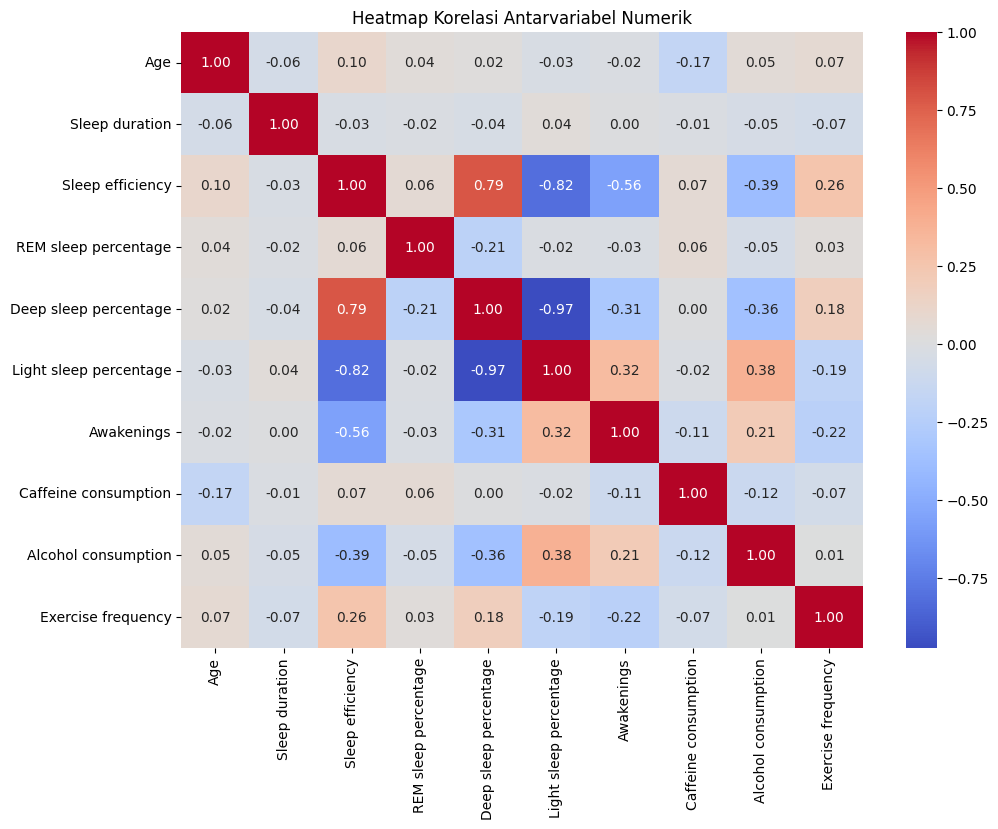

In [ ]:
plt.figure(figsize=(11,8))
sns.heatmap(df.drop(columns='ID').select_dtypes(include='number').corr(),
            annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Heatmap Korelasi Antarvariabel Numerik')
plt.show()

**Temuan Visualisasi 1 (Histogram Sleep Efficiency):** Puncak distribusi ada di kisaran 0,88 sampai 0,93, dan sebagian besar responden memiliki Sleep efficiency di atas 0,7. Distribusinya miring ke kiri (ekor panjang ke arah nilai rendah) sehingga tidak berbentuk lonceng. Selain itu terdapat tumpukan kecil responden dengan efisiensi rendah di sekitar 0,5 (sekitar 25 responden). Artinya kebanyakan responden tidur dengan efisien, tetapi ada sebagian yang kualitas tidurnya jelas lebih buruk. Distribusi target tidak sepenuhnya normal, namun masih dapat digunakan untuk Linear Regression.

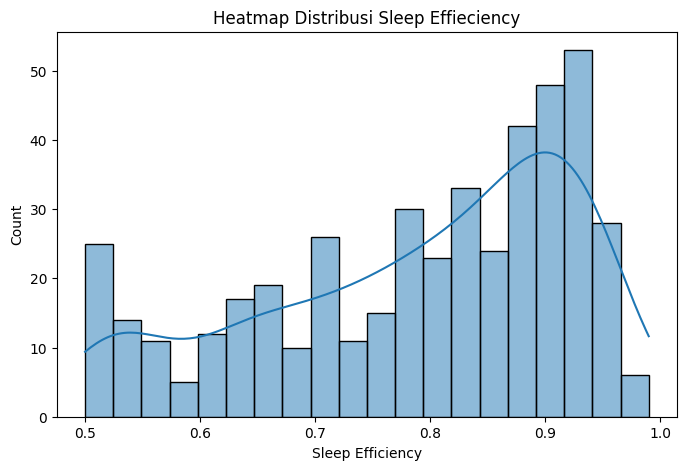

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df['Sleep efficiency'], bins=20, kde=True)
plt.title('Heatmap Distribusi Sleep Effieciency')
plt.xlabel('Sleep Efficiency')
plt.show()

**Temuan Visualisasi 2 (Heatmap Korelasi):**
- Light sleep percentage memiliki korelasi negatif paling kuat dengan Sleep efficiency (−0,82), sedangkan Deep sleep percentage memiliki korelasi positif paling kuat (+0,79). Semakin besar porsi tidur nyenyak dan semakin kecil porsi tidur ringan, semakin tinggi efisiensi tidur.
- Awakenings berkorelasi negatif cukup kuat (−0,56): semakin sering terbangun, efisiensi tidur menurun.
- Alcohol consumption berkorelasi negatif sedang (−0,39), dan Exercise frequency berkorelasi positif lemah sampai sedang (+0,26).
- Age (+0,10), Caffeine consumption (+0,07), REM sleep percentage (+0,06), dan Sleep duration (−0,03) hampir tidak berkorelasi dengan target.
- Deep sleep percentage dan Light sleep percentage saling berkorelasi negatif sangat kuat (−0,97). Ketiga persentase fase tidur (REM, Deep, Light) juga berjumlah 100%. Ini indikasi multikolinearitas yang akan dianalisis lebih lanjut pada A4.

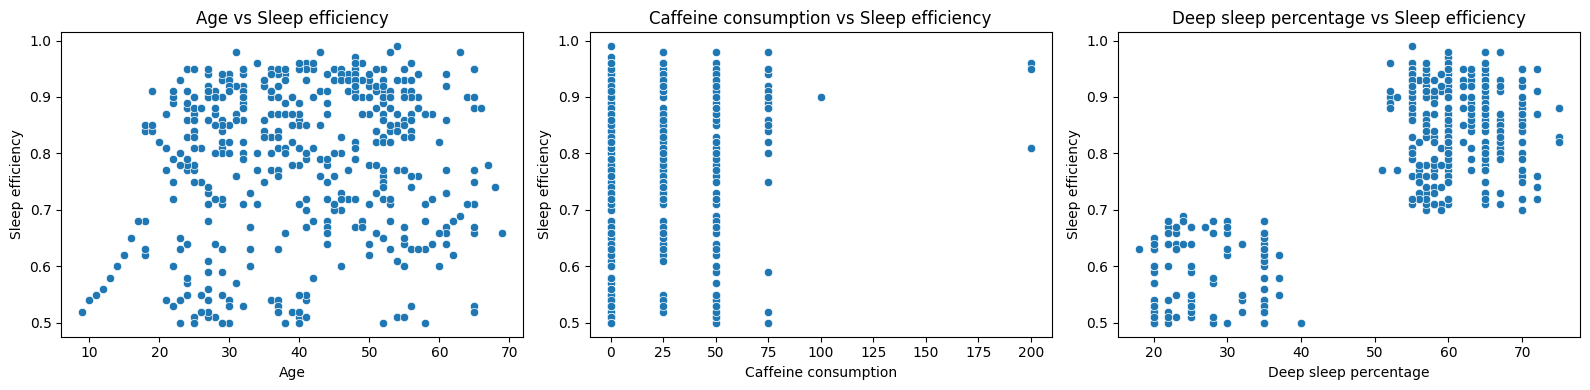

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16,4))
for ax, col in zip(axes, ['Age', 'Caffeine consumption', 'Deep sleep percentage']):
    sns.scatterplot(data=df, x=col, y='Sleep efficiency', ax=ax)
    ax.set_title(f'{col} vs Sleep efficiency')
plt.tight_layout()
plt.show()

**Temuan Visualisasi 3 (Scatter Plot Fitur vs Target):**
- **Deep sleep percentage:** titik terpisah menjadi dua kelompok dengan celah di sekitar 40% sampai 50%. Responden dengan deep sleep di bawah 40% memiliki Sleep efficiency rendah (sekitar 0,5 sampai 0,7), sedangkan yang di atas 50% memiliki efisiensi tinggi (sekitar 0,7 sampai 0,99). Hubungannya positif dan kuat, tetapi bentuknya berupa dua kelompok, bukan garis lurus yang mulus.
- **Age:** secara umum titik tersebar tanpa pola jelas. Satu-satunya pola terlihat pada usia di bawah 20 tahun, di mana efisiensi tidur naik mengikuti umur.
- **Caffeine consumption:** nilainya hanya berupa kelipatan 25 (0, 25, 50, 75, dst.) dengan sebagian besar responden di 0 sampai 50. Hubungannya dengan target lemah. Terdapat nilai ekstrem di 100 dan 200 yang akan dibahas pada bagian outlier (A3). Hasil ini konsisten dengan heatmap korelasi pada visualisasi 2.

## A3. Preprocessing
Pada tahap ini data dibersihkan sebelum dimodelkan: duplikat, missing values, kolom yang tidak dipakai, outlier, dan encoding. Alasan setiap keputusan dijelaskan di bawah tiap langkah.

In [ ]:
# Data duplikat
print('Jumlah duplikat:', df.duplicated().sum())
df = df.drop_duplicates()

# Missing values
print(df.isnull().sum())

Jumlah duplikat: 0
ID                         0
Age                        0
Gender                     0
Bedtime                    0
Wakeup time                0
Sleep duration             0
Sleep efficiency           0
REM sleep percentage       0
Deep sleep percentage      0
Light sleep percentage     0
Awakenings                20
Caffeine consumption      25
Alcohol consumption       14
Smoking status             0
Exercise frequency         6
dtype: int64


**Duplikat:** setelah dicek, tidak ditemukan baris duplikat (0 baris), sehingga tidak ada data yang dibuang. Pengecekan tetap dilakukan untuk memastikan tidak ada responden yang tercatat dua kali.

In [ ]:
# Isi missing values dengan median
kolom_kosong = ['Awakenings', 'Caffeine consumption', 'Alcohol consumption', 'Exercise frequency']
for col in kolom_kosong:
    df[col] = df[col].fillna(df[col].median())

print(df.isnull().sum().sum(), 'missing values tersisa')

0 missing values tersisa


**Missing values:** terdapat data kosong pada empat kolom, yaitu Awakenings (20 baris), Caffeine consumption (25 baris), Alcohol consumption (14 baris), dan Exercise frequency (6 baris), atau sekitar 1% sampai 6% dari 452 baris. Nilai kosong diisi dengan **median**, bukan mean, karena median tidak terpengaruh nilai ekstrem (misalnya kafein 200 mg) dan kolom-kolom ini berupa angka bulat atau kelipatan. Baris tidak dibuang agar jumlah data (452) tidak berkurang.

In [ ]:
# Buang kolom yang tidak dipakai dengan menambahkan errors='ignore' untuk menghindari KeyError saat dijalankan ulang
df = df.drop(columns=['ID', 'Bedtime', 'Wakeup time'], errors='ignore')
df.columns.tolist()

['Age',
 'Gender',
 'Sleep duration',
 'Sleep efficiency',
 'REM sleep percentage',
 'Deep sleep percentage',
 'Light sleep percentage',
 'Awakenings',
 'Caffeine consumption',
 'Alcohol consumption',
 'Smoking status',
 'Exercise frequency']

**Kolom dibuang:** `ID` hanya penanda responden, sedangkan `Bedtime` dan `Wakeup time` berupa tanggal-jam teks; informasinya sudah terwakili oleh `Sleep duration`.

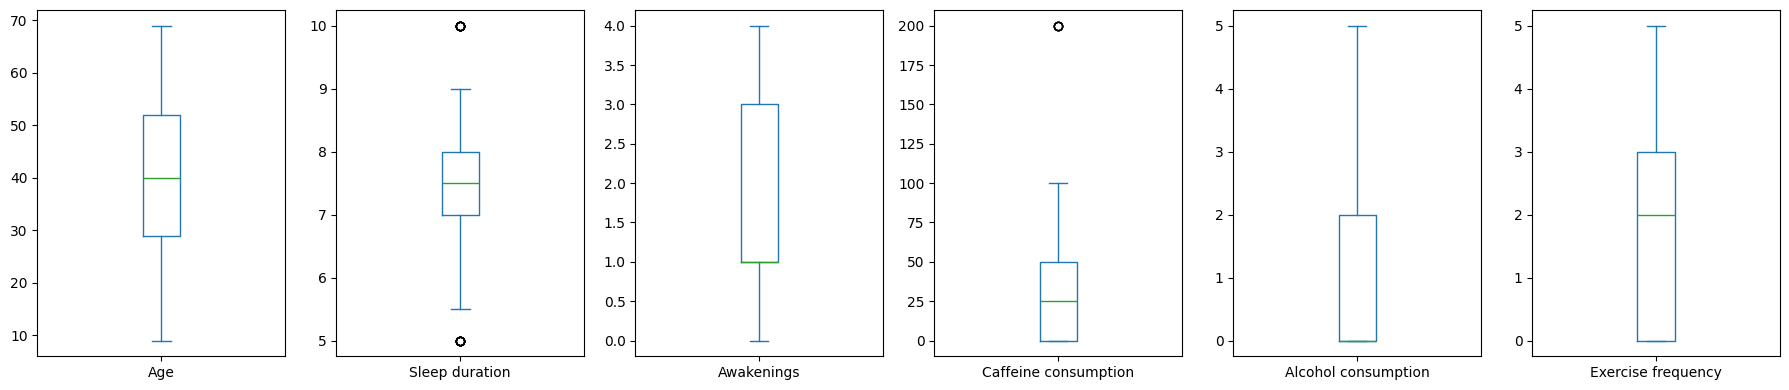

Age: 0 outlier
Sleep duration: 16 outlier
Awakenings: 0 outlier
Caffeine consumption: 4 outlier
Alcohol consumption: 0 outlier
Exercise frequency: 0 outlier


In [ ]:
# Outlier dengan metode IQR
kolom_num = ['Age', 'Sleep duration', 'Awakenings', 'Caffeine consumption', 'Alcohol consumption', 'Exercise frequency']

df[kolom_num].plot(kind='box', subplots=True, layout=(1, 6), figsize=(18, 4))
plt.tight_layout()
plt.show()

for c in kolom_num:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    print(f'{c}: {n} outlier')

**Outlier:** dengan metode IQR, outlier terdeteksi pada dua kolom: Sleep duration (16 data, yaitu durasi tidur 5 jam di bawah batas bawah dan 10 jam di atas batas atas) dan Caffeine consumption (4 data, yaitu konsumsi kafein 200 mg). Kolom Age, Awakenings, Alcohol consumption, dan Exercise frequency tidak memiliki outlier. Outlier **dipertahankan** karena nilainya masuk akal secara nyata (kafein 200 mg setara sekitar 2 cangkir kopi, tidur 5 atau 10 jam masih wajar) dan bukan kesalahan input. Jumlahnya juga kecil dibanding 452 data (20 data, sekitar 4%), sehingga pengaruhnya terhadap model kecil.

In [ ]:
# Encoding fitur kategorikal
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})
df['Smoking status'] = df['Smoking status'].map({'No': 0, 'Yes': 1})
print('NaN setelah encoding:', df[['Gender', 'Smoking status']].isnull().sum().sum())
df.head()

NaN setelah encoding: 0


,Age,Gender,Sleep duration,Sleep efficiency,REM sleep percentage,Deep sleep percentage,Light sleep percentage,Awakenings,Caffeine consumption,Alcohol consumption,Smoking status,Exercise frequency
0,65,1,6.0,0.88,18,70,12,0.0,0.0,0.0,1,3.0
1,69,0,7.0,0.66,19,28,53,3.0,0.0,3.0,1,3.0
2,40,1,8.0,0.89,20,70,10,1.0,0.0,0.0,0,3.0
3,40,1,6.0,0.51,23,25,52,3.0,50.0,5.0,1,1.0
4,57,0,8.0,0.76,27,55,18,3.0,0.0,3.0,0,3.0


**Encoding:** model regresi hanya menerima angka, sehingga `Gender` diubah menjadi Male=0, Female=1 dan `Smoking status` menjadi No=0, Yes=1. Keduanya biner sehingga label encoding sudah cukup (tidak perlu one-hot).

**Scaling:** Linear Regression tidak membutuhkan scaling agar hasilnya benar, dan model utama dibiarkan pada skala asli supaya koefisien mudah diinterpretasikan. Scaling (StandardScaler) hanya dipakai di A6 untuk membandingkan besar pengaruh antarfitur, dan dilakukan **setelah split** agar tidak terjadi data leakage.

## A4. Pemilihan Fitur
Fitur dipilih berdasarkan korelasi dengan target dan pengecekan multikolinearitas (VIF).

In [ ]:
# Korelasi fitur dengan target
df.corr()['Sleep efficiency'].drop('Sleep efficiency').sort_values()

,Sleep efficiency
Light sleep percentage,-0.819204
Awakenings,-0.552179
Alcohol consumption,-0.381249
Smoking status,-0.290026
Sleep duration,-0.027467
Gender,-0.010062
REM sleep percentage,0.062362
Caffeine consumption,0.062904
Age,0.098357
Exercise frequency,0.257688


In [ ]:
# VIF: semua fitur kandidat
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

def hitung_vif(X):
    # Hanya menghitung VIF untuk kolom numerik tanpa nilai NaN
    X_clean = X.select_dtypes(include='number').dropna(axis=1, how='all').dropna()
    Xc = add_constant(X_clean)
    return pd.DataFrame({
        'fitur': X_clean.columns,
        'VIF': [variance_inflation_factor(Xc.values, i+1) for i in range(X_clean.shape[1])]
    })

X_semua = df.drop(columns='Sleep efficiency', errors='ignore')
print('VIF sebelum membuang Light sleep:')
display(hitung_vif(X_semua))

VIF sebelum membuang Light sleep:


/tmp/ipykernel_3038/3852140755.py:11: UserWarning: The design matrix is poorly conditioned (condition number=1.06e+16). VIF calculations may be numerically unstable.
  'VIF': [variance_inflation_factor(Xc.values, i+1) for i in range(X_clean.shape[1])]
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/

,fitur,VIF
0,Age,1.094626e+00
1,Gender,1.265033e+00
2,Sleep duration,1.014451e+00
3,REM sleep percentage,1.000800e+15
4,Deep sleep percentage,1.000800e+15
5,Light sleep percentage,1.000800e+15
6,Awakenings,1.194517e+00
7,Caffeine consumption,1.102386e+00
8,Alcohol consumption,1.203665e+00
9,Smoking status,1.103170e+00


In [ ]:
# VIF setelah membuang Light sleep percentage
X_pilih = X_semua.drop(columns='Light sleep percentage')
print('VIF setelah membuang Light sleep:')
display(hitung_vif(X_pilih))

VIF setelah membuang Light sleep:


,fitur,VIF
0,Age,1.094626
1,Gender,1.265033
2,Sleep duration,1.014451
3,REM sleep percentage,1.112323
4,Deep sleep percentage,1.423856
5,Awakenings,1.194517
6,Caffeine consumption,1.102386
7,Alcohol consumption,1.203665
8,Smoking status,1.103170
9,Exercise frequency,1.157017


**Hasil pemilihan fitur:**
- **Dibuang: `Light sleep percentage`.** REM + Deep + Light = 100%, sehingga ketiganya saling bergantung (multikolinearitas). VIF-nya sangat tinggi (isi angkanya), dan korelasinya dengan Deep sleep −0,97. Light dipilih untuk dibuang karena informasinya sudah terwakili oleh REM dan Deep.
- **Dipertahankan:** Age, Gender, Sleep duration, REM sleep percentage, Deep sleep percentage, Awakenings, Caffeine consumption, Alcohol consumption, Smoking status, Exercise frequency. Setelah Light dibuang, semua VIF di bawah 10 (isi angkanya) sehingga tidak ada multikolinearitas yang mengganggu.
- Age, Caffeine, dan Sleep duration berkorelasi lemah dengan target, tetapi tetap dipertahankan karena secara logika berhubungan dengan kualitas tidur dan tidak menimbulkan multikolinearitas.

## A5. Pembagian Data
Data dibagi 80% data latih dan 20% data uji dengan `random_state=42` agar hasil selalu sama setiap dijalankan.

In [ ]:
from sklearn.model_selection import train_test_split

fitur = X_pilih.columns.tolist()
X = df[fitur]
y = df['Sleep efficiency']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print('Data latih:', X_train.shape, '| Data uji:', X_test.shape)

Data latih: (361, 10) | Data uji: (91, 10)


## A6. Pemodelan
Model `LinearRegression` dilatih pada data latih (skala asli), lalu koefisien dan intercept ditampilkan.

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print('Intercept:', round(model.intercept_, 4))
koef = pd.DataFrame({'Fitur': fitur, 'Koefisien': model.coef_}).sort_values('Koefisien')
koef

Intercept: 0.3407


,Fitur,Koefisien
8,Smoking status,-0.039292
5,Awakenings,-0.034260
1,Gender,-0.006628
7,Alcohol consumption,-0.004593
6,Caffeine consumption,0.000121
0,Age,0.000819
9,Exercise frequency,0.003816
2,Sleep duration,0.004427
4,Deep sleep percentage,0.005722
3,REM sleep percentage,0.006464


In [ ]:
# Koefisien terstandarisasi (fit scaler hanya di data latih)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit hanya di data latih yang sudah bersih

model_s = LinearRegression().fit(X_train_s, y_train)
koef_s = pd.DataFrame({'Fitur': fitur, 'Koefisien (standar)': model_s.coef_})
koef_s['Pengaruh (abs)'] = koef_s['Koefisien (standar)'].abs()
koef_s.sort_values('Pengaruh (abs)', ascending=False)

,Fitur,Koefisien (standar),Pengaruh (abs)
4,Deep sleep percentage,0.089491,0.089491
5,Awakenings,-0.045919,0.045919
3,REM sleep percentage,0.022750,0.022750
8,Smoking status,-0.018264,0.018264
0,Age,0.010718,0.010718
7,Alcohol consumption,-0.007291,0.007291
9,Exercise frequency,0.005443,0.005443
2,Sleep duration,0.003867,0.003867
6,Caffeine consumption,0.003649,0.003649
1,Gender,-0.003313,0.003313


**Interpretasi koefisien** (fitur lain dianggap tetap):
- **Intercept (0,3407)**: prediksi Sleep efficiency jika semua fitur bernilai 0. Angka ini hanya titik awal matematis dan tidak punya arti nyata, karena misalnya Age = 0 atau Sleep duration = 0 tidak ada di data.
- **Deep sleep percentage (+0,0057)**: setiap kenaikan 1 poin persen deep sleep menaikkan Sleep efficiency sebesar sekitar 0,0057. Tanda positif sesuai heatmap. Karena Light sleep dibuang (REM + Deep + Light = 100%), kenaikan Deep sleep berarti porsi Light sleep ikut turun, sehingga koefisien ini dibaca relatif terhadap Light sleep.
- **REM sleep percentage (+0,0065)**: setiap kenaikan 1 poin persen REM menaikkan Sleep efficiency sekitar 0,0065, juga dibaca relatif terhadap Light sleep yang dibuang.
- **Awakenings (−0,0343)**: setiap 1 kali terbangun tambahan menurunkan Sleep efficiency sebesar sekitar 0,0343. Sesuai logika, semakin sering terbangun semakin kecil waktu tidur efektif.
- **Smoking status (−0,0393)**: responden perokok memiliki Sleep efficiency rata-rata sekitar 0,0393 lebih rendah dibanding bukan perokok. Ini koefisien terbesar pada skala asli, tetapi karena fitur biner (0/1), perbandingan yang adil dilihat dari koefisien terstandarisasi.
- **Alcohol consumption (−0,0046)**: setiap tambahan 1 oz alkohol menurunkan Sleep efficiency sekitar 0,0046. Arahnya sesuai heatmap (korelasi negatif).
- **Exercise frequency (+0,0038)**: setiap tambahan 1 kali olahraga per minggu menaikkan Sleep efficiency sekitar 0,0038.
- **Sleep duration (+0,0044)**: setiap tambahan 1 jam tidur menaikkan Sleep efficiency sekitar 0,0044, pengaruh yang sangat kecil.
- **Gender (−0,0066)**: responden perempuan (Female = 1) memiliki Sleep efficiency sekitar 0,0066 lebih rendah dibanding laki-laki, selisih yang sangat kecil.
- **Age (+0,0008)** dan **Caffeine consumption (+0,0001)**: koefisiennya mendekati nol, artinya hampir tidak berpengaruh terhadap Sleep efficiency. Ini konsisten dengan korelasi lemah di heatmap A2.

Dari koefisien terstandarisasi (setiap kenaikan 1 standar deviasi), fitur yang paling berpengaruh adalah **Deep sleep percentage (0,0895)**, diikuti **Awakenings (−0,0459)**, **REM sleep percentage (0,0228)**, dan **Smoking status (−0,0183)**. Fitur lainnya berpengaruh kecil (nilai mutlak di bawah 0,011). Tanda koefisien umumnya sesuai dengan arah korelasi di heatmap A2: Deep sleep, REM, dan Exercise positif, sedangkan Awakenings dan Alcohol negatif.

## A7. Evaluasi Model
Pada tahap ini, model dievaluasi menggunakan metrik MAE, MSE, RMSE, dan R-squared pada data latih dan data uji untuk melihat seberapa baik model memprediksi nilai aktual

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Lakukan prediksi pada data latih dan uji

In [ ]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# 2. Fungsi untuk menghitung dan menampilkan metrik

In [ ]:
def evaluasi_metriks(y_true, y_pred, nama_data):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    print(f"Evaluasi pada data {nama_data}:")
    print(f"MAE: {mae:.4f}")
    print(f"MSE: {mse:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R-squared: {r2:.4f}")

# 3. Panggil fungsi untuk data latih dan uji

In [ ]:
evaluasi_metriks(y_train, y_train_pred, "Data Latih (Train)")
evaluasi_metriks(y_test, y_test_pred, "Data Uji (Test)")

Evaluasi pada data Data Latih (Train):
MAE: 0.0483
MSE: 0.0035
RMSE: 0.0595
R-squared: 0.8052
Evaluasi pada data Data Uji (Test):
MAE: 0.0506
MSE: 0.0038
RMSE: 0.0619
R-squared: 0.7940


# 4. Plot nilai Aktual vs Prediksi (Data Uji)

<Axes: xlabel='Sleep efficiency'>

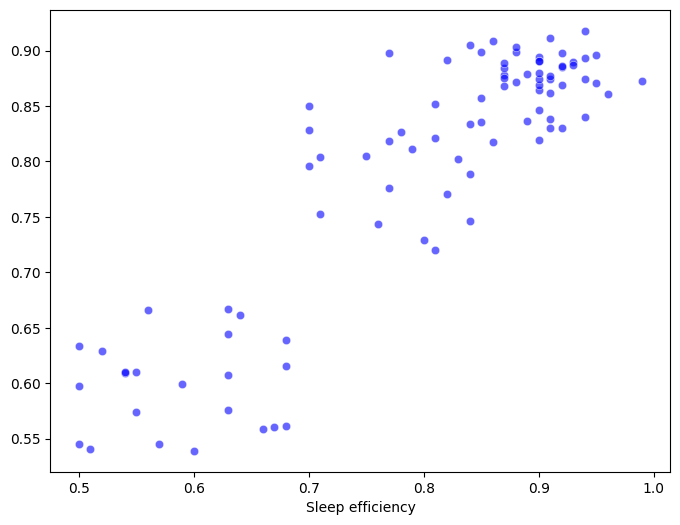

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_test_pred, alpha=0.6, color='blue')

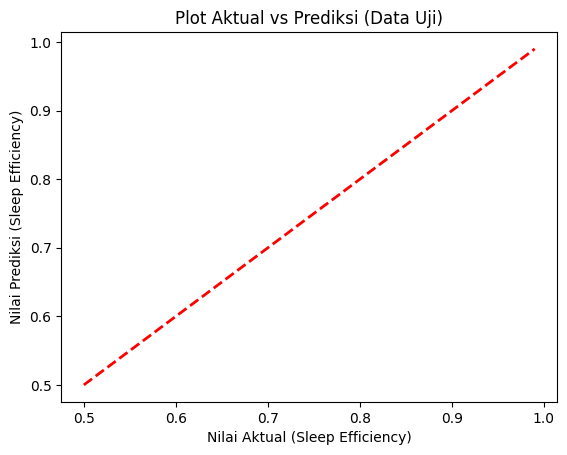

In [ ]:
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
plt.xlabel('Nilai Aktual (Sleep Efficiency)')
plt.ylabel('Nilai Prediksi (Sleep Efficiency)')
plt.title('Plot Aktual vs Prediksi (Data Uji)')
plt.show()

# 5. Residual Plot (Data Uji)

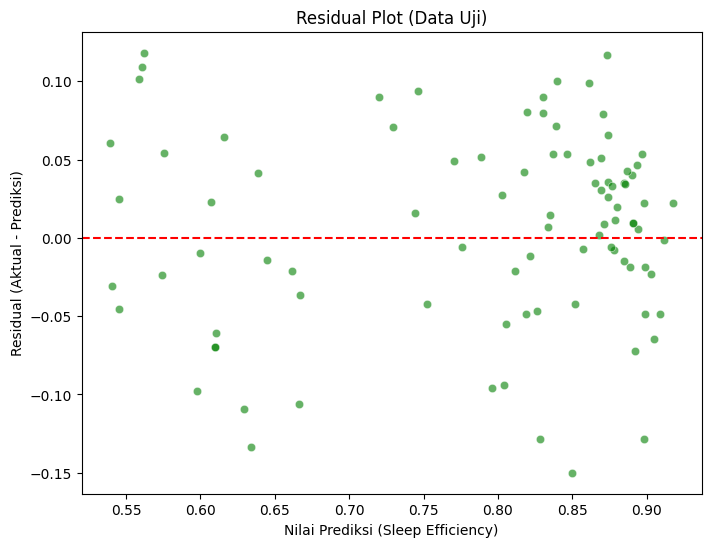

In [ ]:
residuals = y_test - y_test_pred
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test_pred, y=residuals, alpha=0.6, color='green')
plt.axhline(y=0, color='r', linestyle='--') # Garis nol
plt.xlabel('Nilai Prediksi (Sleep Efficiency)')
plt.ylabel('Residual (Aktual - Prediksi)')
plt.title('Residual Plot (Data Uji)')
plt.show()

## A8. Analisis Performa

**1. Seberapa baik model memprediksi target?**

Berdasarkan hasil evaluasi, model memiliki nilai R-squared (R2) sebesar **0.7940** pada data uji. Ini berarti model mampu menjelaskan sekitar **79.4%** variansi dari kualitas tidur (Sleep efficiency). Nilai **MAE** sebesar **0.0506** menunjukkan bahwa rata-rata prediksi model meleset sekitar **0.05** poin dari nilai aktual (pada skala 0-1). Secara umum, model sudah sangat baik dalam menangkap pola, karena error yang dihasilkan cukup kecil dan R² yang tinggi.

**2. Apakah terjadi Overfitting atau Underfitting?**

Dengan membandingkan metrik data latih dan data uji:
1. R² Data Latih: **0.8052**
2. R² Data Uji: **0.7940**
3. RMSE Data Latih: **0.0595**
4. RMSE Data Uji: **0.0619**

Selisih R² antara data latih dan data uji sangat kecil, yaitu hanya sekitar **0.0112** (0.8052 - 0.7940). Model tidak menunjukkan adanya overfitting karena performanya di data uji tidak turun drastis. Model tidak hanya sekadar menghafal data latih. Model juga tidak underfitting karena nilai R² pada data uji sudah tinggi (mendekati 0.8). Ini menandakan model berada di kondisi Good Fit (pas).

**3. Fitur yang paling berpengaruh?**

Berdasarkan koefisien standarisasi yang dihasilkan pada A6, fitur yang paling berpengaruh adalah:


1. **Deep sleep percentage** (koefisien positif, +0.0895): Semakin besar persentase tidur nyenyak, semakin tinggi efisiensi tidur. Hal ini sangat logis secara medis karena deep sleep adalah fase tidur paling restoratif.
2. **Awakenings** (koefisien negatif, -0.0459): Semakin sering seseorang terbangun di malam hari, semakin rendah efisiensi tidurnya.

**4. Keterbatasan Model**

1. **Hubungan Linear:** Linear Regression mengasumsikan hubungan garis lurus antar fitur dan target. Pada kenyataannya, faktor kualitas tidur bisa sangat kompleks dan non-linear (terlihat dari scatter plot Deep sleep di A2 yang membentuk dua klaster).
2. **Outlier  Dipertahankan:** Pada tahap preprocessing, kita mempertahankan outlier (seperti kafein 200mg dan durasi tidur 10 jam). Hal ini bisa sedikit menarik garis regresi.
3. **Informasi Waktu Hilang:** Kolom 'Bedtime' dan 'Wakeup time' dibuang di A3. Padahal, jam berapa seseorang mulai tidur (misal dini hari vs jam 9 malam) sangat memengaruhi efisiensi, dan informasinya tidak sepenuhnya diwakili oleh 'Sleep duration'.
4. **Faktor Eksternal:** Model ini belum memasukkan faktor psikologis (stres, kecemasan) atau kondisi lingkungan (kebisingan, suhu kamar) yang sebenarnya sangat memengaruhi kualitas tidur.
